In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.patches import Patch

size = 600
Nmax = 200
parameters = [0+0j, -1+0j, -0.123+0.745j, 1+0j]
parameter_labels = ["A: c = 0", "B: c = -1", "C: c = -0.123 + 0.745i", "D: c = 1"]
cmap = plt.get_cmap("turbo").copy()
cmap.set_bad("black")
norm = PowerNorm(gamma=0.25, vmin=0, vmax=Nmax)
color_ticks = [0, 1, 5, 20, 50, 100, 200]


def complex_grid(x_bounds, y_bounds, size):
    x_edges = np.linspace(*x_bounds, size+1)
    y_edges = np.linspace(*y_bounds, size+1)
    x = (x_edges[:-1]+x_edges[1:])/2
    y = (y_edges[:-1]+y_edges[1:])/2
    return x[None, :] + 1j*y[:, None]


def escape_time(z0, c, radius, nmax):
    z_initial, c_grid = np.broadcast_arrays(np.asarray(z0, dtype=complex),
                                           np.asarray(c, dtype=complex))
    z = z_initial.copy()
    escaped_at = np.full(z.shape, -1, dtype=np.int32)
    active = np.ones(z.shape, dtype=bool)
    escaped = np.abs(z) > radius
    escaped_at[escaped] = 0
    active[escaped] = False
    for n in range(1, nmax+1):
        if not active.any():
            break
        z[active] = z[active]**2 + c_grid[active]
        escaped = active & (np.abs(z) > radius)
        escaped_at[escaped] = n
        active[escaped] = False
    return escaped_at


def show_fractal(ax, escaped_at, extent, title, plane):
    image = ax.imshow(np.ma.masked_equal(escaped_at, -1), origin="lower",
                      extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    ax.set(title=title, xlabel=f"Re {plane}", ylabel=f"Im {plane}")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(extent[:2])
    ax.set_ylim(extent[2:])
    return image


mandelbrot_extent = [-2, 1, -1.5, 1.5]
julia_extent = [-2, 2, -2, 2]
c_grid = complex_grid((-2, 1), (-1.5, 1.5), size)
z_grid = complex_grid((-2, 2), (-2, 2), size)
mandelbrot = escape_time(0j, c_grid, 2, Nmax)
julia = {c: escape_time(z_grid, c, max(2, abs(c)), Nmax) for c in parameters}

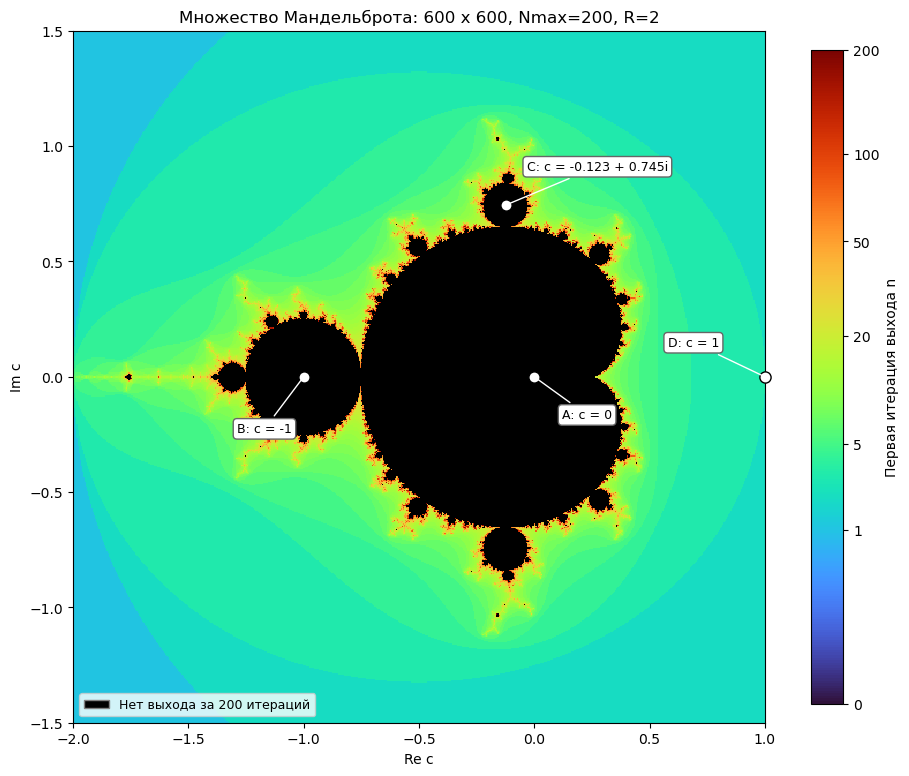

In [2]:
fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
image = show_fractal(ax, mandelbrot, mandelbrot_extent,
                     f"Множество Мандельброта: {size} x {size}, Nmax={Nmax}, R=2", "c")
offsets = [(20, -30), (-48, -40), (15, 25), (-70, 22)]
for c, label, offset in zip(parameters, parameter_labels, offsets):
    ax.scatter(c.real, c.imag, s=65, color="white", edgecolor="black", zorder=4, clip_on=False)
    ax.annotate(label, (c.real, c.imag), xytext=offset, textcoords="offset points",
                fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.4"),
                arrowprops=dict(arrowstyle="-", color="white"), zorder=5)
bar = fig.colorbar(image, ax=ax, shrink=0.85, ticks=color_ticks)
bar.set_label("Первая итерация выхода n")
ax.legend(handles=[Patch(facecolor="black", edgecolor="gray", label="Нет выхода за 200 итераций")],
          loc="lower left", fontsize=9)
plt.show()

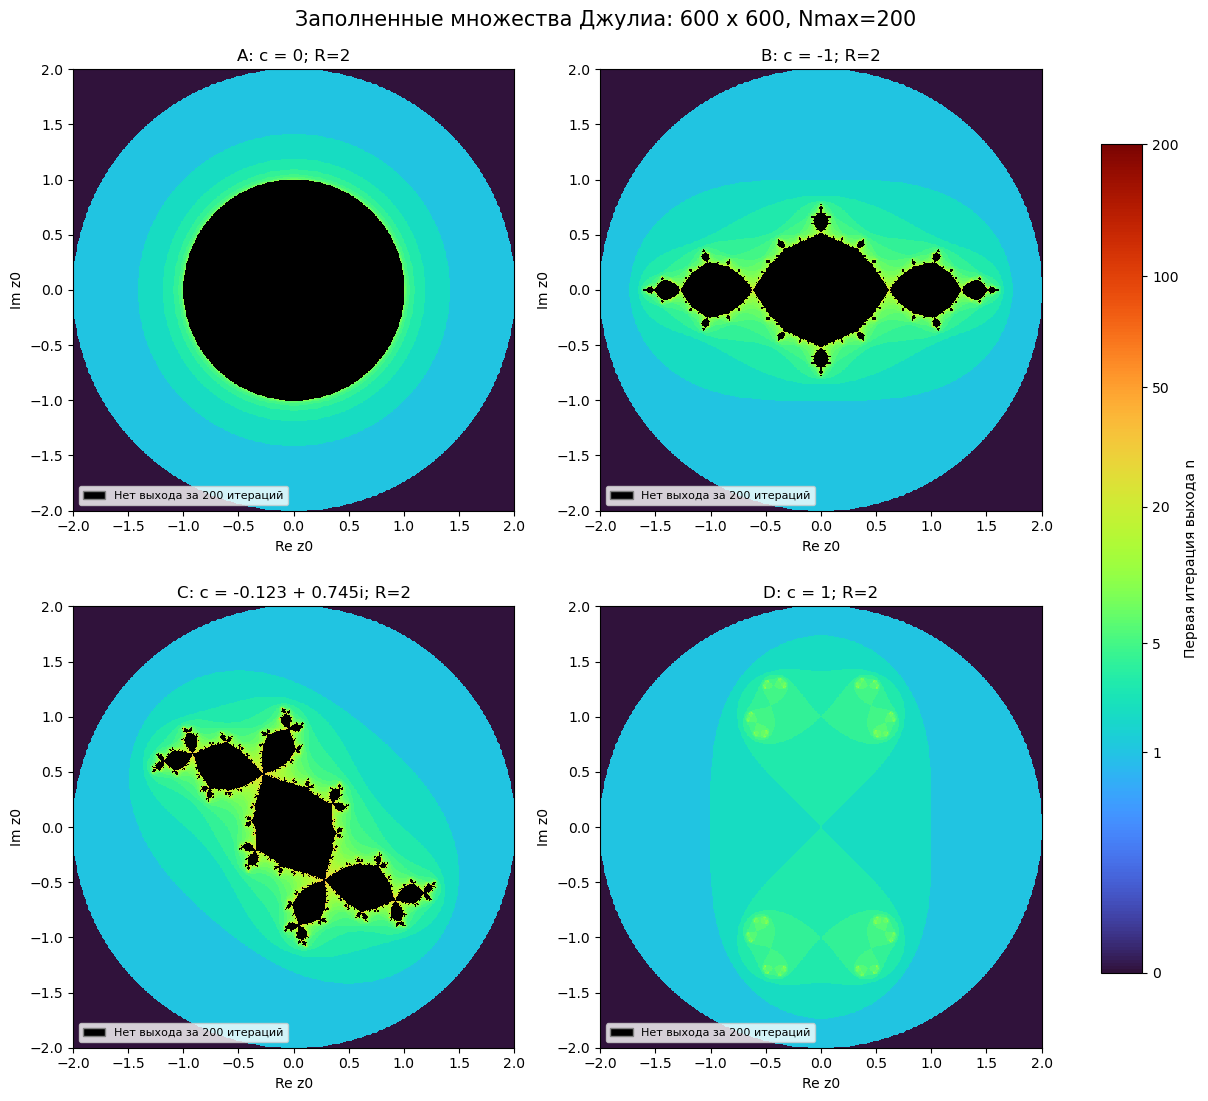

                     c      Не вышли за Nmax     Всего узлов
                    0j                 70688          360000
               (-1+0j)                 31824          360000
       (-0.123+0.745j)                 29444          360000
                (1+0j)                     0          360000


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for ax, c, label in zip(axes.flat, parameters, parameter_labels):
    image = show_fractal(ax, julia[c], julia_extent,
                         f"{label}; R={max(2, abs(c)):g}", "z0")
    ax.legend(handles=[Patch(facecolor="black", edgecolor="gray", label="Нет выхода за 200 итераций")],
              loc="lower left", fontsize=8)
fig.suptitle(f"Заполненные множества Джулиа: {size} x {size}, Nmax={Nmax}", fontsize=15)
bar = fig.colorbar(image, ax=axes, shrink=0.8, ticks=color_ticks)
bar.set_label("Первая итерация выхода n")
plt.show()

print(f"{'c':>22} {'Не вышли за Nmax':>21} {'Всего узлов':>15}")
for c in parameters:
    print(f"{str(c):>22} {np.count_nonzero(julia[c] == -1):21d} {size*size:15d}")

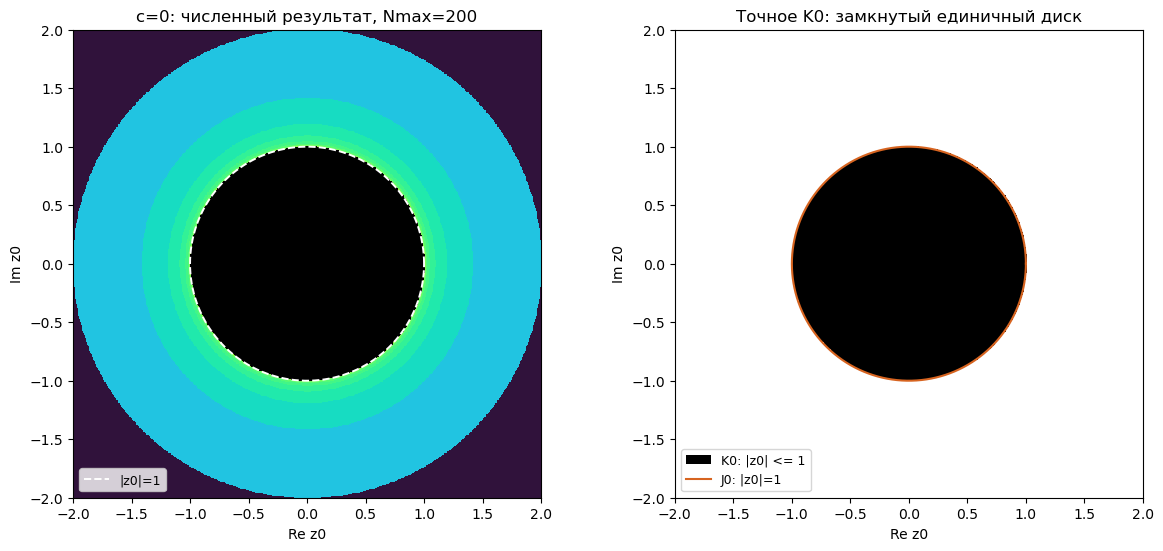

In [4]:
numerical_disk = julia[0j] == -1
exact_disk = np.abs(z_grid) <= 1
false_inside = np.count_nonzero(numerical_disk & ~exact_disk)
false_outside = np.count_nonzero(~numerical_disk & exact_disk)
phi = np.linspace(0, 2*np.pi, 1500)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)
image = show_fractal(axes[0], julia[0j], julia_extent,
                     f"c=0: численный результат, Nmax={Nmax}", "z0")
axes[0].plot(np.cos(phi), np.sin(phi), color="white", ls="--", lw=1.4, label="|z0|=1")
axes[0].legend(loc="lower left", fontsize=9)
axes[1].imshow(exact_disk, origin="lower", extent=julia_extent, cmap="binary",
               vmin=0, vmax=1, interpolation="nearest")
axes[1].plot(np.cos(phi), np.sin(phi), color="#d76420", lw=1.5, label="J0: |z0|=1")
axes[1].set(title="Точное K0: замкнутый единичный диск", xlabel="Re z0", ylabel="Im z0")
axes[1].set_aspect("equal", adjustable="box")
axes[1].legend(handles=[Patch(facecolor="black", label="K0: |z0| <= 1"),
                        axes[1].lines[0]], loc="lower left", fontsize=9)
plt.show()